# Kenya County Fertilizer Affordability 2026

Kilograms of maize, beans or potatoes one bag of DAP, CAN, urea or NPK costs. A free sample from [NuaSense](https://agriculture-data.com), East African agricultural data; also on [Hugging Face](https://huggingface.co/datasets/nuasense/kenya-county-fertilizer-affordability) (CC BY-NC 4.0).

In [1]:
import glob, os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#ecebe7", "axes.axisbelow": True, "font.size": 10})
BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"

def load(name, hf_url):
    # On Kaggle the CSV sits under /kaggle/input; in Colab or on your machine the same table
    # is read straight from Hugging Face.
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"**/{name}", recursive=True)
    return pd.read_csv(hits[0]) if hits else pd.read_parquet(hf_url)

df = load("kenya_county_fertilizer_affordability_2026.csv", "https://huggingface.co/datasets/nuasense/kenya-county-fertilizer-affordability/resolve/main/data/affordability/affordability.parquet")
print(f"{len(df):,} rows")
df.head()

363 rows


,country,county_id,county_name,month,fertilizer,fertilizer_kes_per_kg,fertilizer_observations,crop,crop_kes_per_kg,crop_observations,kg_crop_per_50kg_bag
0,KE,bungoma,Bungoma,2026-06,can,100.0,1,dry_beans,85.0,11,58.8
1,KE,bungoma,Bungoma,2026-06,can,100.0,1,dry_maize,62.5,6,80.0
2,KE,bungoma,Bungoma,2026-06,can,100.0,1,irish_potatoes,55.0,6,90.9
3,KE,bungoma,Bungoma,2026-06,urea,124.0,1,dry_beans,85.0,11,72.9
4,KE,bungoma,Bungoma,2026-06,urea,124.0,1,dry_maize,62.5,6,99.2


## DAP against maize, latest month per county

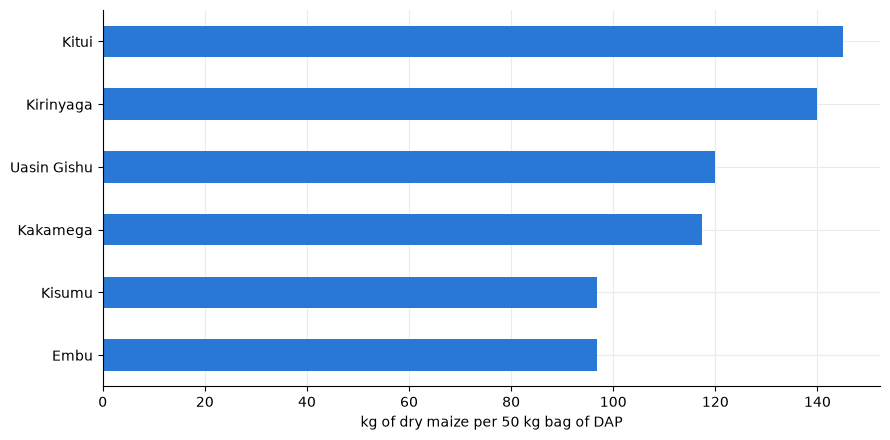

,county_name,month,fertilizer_kes_per_kg,crop_kes_per_kg,kg_crop_per_50kg_bag
19,Embu,2026-04,126.0,65.00,96.9
331,Kisumu,2026-10,120.0,61.90,96.9
136,Kakamega,2026-10,128.0,54.55,117.3
361,Uasin Gishu,2026-09,120.0,50.00,120.0
241,Kirinyaga,2026-10,140.0,50.00,140.0
349,Kitui,2026-10,145.0,50.00,145.0


In [2]:
dm = df[(df.fertilizer == "dap") & (df.crop == "dry_maize")]
latest = dm.sort_values("month").groupby("county_name").tail(1).sort_values("kg_crop_per_50kg_bag")
ax = latest.plot.barh(x="county_name", y="kg_crop_per_50kg_bag", color=BLUE, legend=False)
ax.set_xlabel("kg of dry maize per 50 kg bag of DAP"); ax.set_ylabel("")
plt.tight_layout(); plt.show()
latest[["county_name", "month", "fertilizer_kes_per_kg", "crop_kes_per_kg", "kg_crop_per_50kg_bag"]]

## Which crop pays for fertilizer best

Median kilograms of each crop per bag, across counties and months.

In [3]:
df.pivot_table(index="fertilizer", columns="crop", values="kg_crop_per_50kg_bag", aggfunc="median").round(0)

crop,dry_beans,dry_maize,irish_potatoes
fertilizer,,,
can,27.0,76.0,62.0
dap,40.0,108.0,87.0
npk,36.0,100.0,79.0
urea,34.0,99.0,78.0


## Through the year

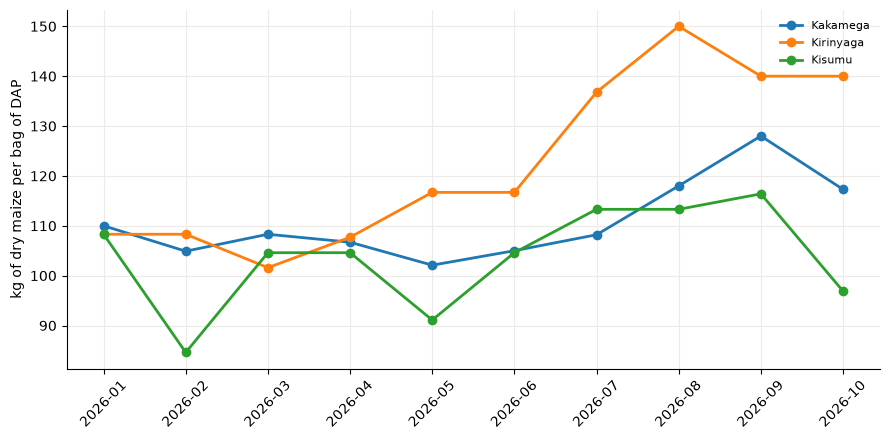

In [4]:
for county, g in dm.groupby("county_name"):
    if g.month.nunique() >= 3:
        g = g.sort_values("month")
        plt.plot(g.month, g.kg_crop_per_50kg_bag, marker="o", linewidth=2, label=county)
plt.ylabel("kg of dry maize per bag of DAP"); plt.xticks(rotation=45); plt.legend(fontsize=8, frameon=False)
plt.tight_layout(); plt.show()

## The full data

Both prices come from every recorded market price. The NuaSense API serves them by market and day since 2021, plus the asking prices of fertilizer sellers and the affordability index per county.

```
pip install nuasense
```

A key with a free monthly allowance comes from [platform.nuasense.com](https://platform.nuasense.com/start). On Kaggle, store it as a secret named `NUASENSE_API_KEY` (Add-ons → Secrets). Fields and filters: [agriculture-data.com](https://agriculture-data.com/datasets/price-intelligence/commodity-prices/).

In [5]:
# Runs only when a NuaSense key is available (Kaggle secret NUASENSE_API_KEY or an environment variable).
try:
    from kaggle_secrets import UserSecretsClient
    os.environ.setdefault("NUASENSE_API_KEY", UserSecretsClient().get_secret("NUASENSE_API_KEY"))
except Exception:
    pass

if os.environ.get("NUASENSE_API_KEY"):
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "nuasense"], check=False)
    import nuasense
    ns = nuasense.Client()
    rows = ns.rows("/market/prices", start="-30d", limit=200, commodity="fertilizer", variety="dap", county="kakamega", source="kamis")
    display(pd.DataFrame(rows).head())
else:
    print("No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.")

No NUASENSE_API_KEY set: add it as a Kaggle secret (Add-ons -> Secrets) to read the full series.
